# Offline: conformal prediction under label, domain and device shift

ICP, FCP + $w_{oracle}$, FCP, FCP + Mondrian and FCP + $w_{label}$ (in-sample) under the same shifts as the online scenario; `DRAWS` draws per case. **Every case uses the whole test set** (test split, corrupted test split or external set, with its own class frequencies $q_{\text{test}}$), and the **calibration set** (16·C train images) takes a class mix $q_{\text{cal}}$ chosen with respect to it:

| case | test set (whole, own frequencies) | calibration mix $q_{\text{cal}}$ |
|---|---|---|
| **clean** (reference, KL = 0) | test split | $q_{\text{test}}$ |
| **device shift** (blur / noise L1–L5) | corrupted test split (the same images as clean) | $q_{\text{test}}$ |
| **domain shift** (ZURICH, GERTYCH for SICAPv2; DeepDRiD for MESSIDOR) | external set | $q_{\text{test}}$ of the external set |
| **label shift** (KL grid) | test split | Dirichlet draw with $\mathrm{KL}(q_{\text{cal}} \Vert q_{\text{test}})$ = KL, redrawn until the train split has enough images of every class for it |

So clean, device and domain shift have **no label shift** (any loss of coverage comes from the images), and label shift changes only the class mix. The calibration set has at least one image per class and never more images of a class than the train split has (no repeated images). Since the test set is fixed, the draws are random calibration sets.

**Draws and seeds.** Within a draw, all the methods use the same calibration set (paired comparison). Clean and all the device levels also share it (same mix $q_{\text{test}}$, seed `kl_grid_seed(dataset, 900, draw)`), so the device curves only change the corruption; domain shift (seed offset of the external set) and every KL of label shift draw their own.

| name | method |
|---|---|
| ICP | split CP, zero-shot classifier |
| FCP+$w_{oracle}$ | FCA with label weights $q_{\text{test}} / q_{\text{cal}}$ (true test class mix) |
| FCP | full conformal adaptation (FCA) |
| FCP+mondrian | FCA, one threshold per class |
| FCP+$w_{label}$ | FCA with label weights $\hat q / q_{\text{cal}}$, $\hat q$ by BBSE soft on FCA's soft labels, confusion matrix in-sample on the calibration set |

The test sets come from the test split (or an external set), so every case also carries the dataset's own train → test covariate shift; **clean** measures it alone.

In [1]:
import sys, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, os.path.abspath('../'))  # project root
from utils.embedding_datasets import load_dataset, load_external_test_set, EXTERNAL_TEST_SETS
from utils.data_sampling import sample_calibration_capped
from utils.linear_classifier import linear_predict
from utils.distribution_shift import dirichlet_draw_feasible, kl_grid_seed
from utils.progress import status, hms
from utils.results_cache import load_draws
from conformal.conformal_prediction import scp, fca_sets, fca_soft_labels
from conformal.metrics import set_metrics
from conformal.label_shift import calibration_soft_labels, confusion_soft, bbse, label_weights

DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'local_data', 'embeddings'))
FIG_DIR = 'results/figures'
os.makedirs(FIG_DIR, exist_ok=True)
ALPHA, SHOTS, DRAWS = 0.10, 16, 100
TEST_CAP = None          # at most TEST_CAP test images (a fixed random subset per dataset and draw, shared by the cases); None = all
RESULTS_CSV = (f'results/offline_shifts_testmix_{DRAWS}draws.csv' if TEST_CAP is None else
               f'results/offline_shifts_testmix_{DRAWS}draws-{TEST_CAP}_test_cap.csv')
KEYS = ['dataset', 'shift', 'draw', 'method']
KLS = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 0.8]
CORRUPTIONS, LEVELS = ['blur', 'noise'], [1, 2, 3, 4, 5]
DATASETS = ['CheXpert5x200', 'nihlt', 'covid', 'NCT', 'SICAPv2', 'Skin', 'MESSIDOR', 'FIVES', 'MMAC']
EXTERNAL = {e: v['source'] for e, v in EXTERNAL_TEST_SETS.items()}
DEVICE = [f'{c} L{l}' for c in CORRUPTIONS for l in LEVELS]
LABEL = [f'label shift (KL = {kl:g})' for kl in KLS]
SHIFTS = ['clean'] + DEVICE + list(EXTERNAL) + LABEL           # index = seed offset of the shift
METHODS = ['ICP', 'FCP+$w_{oracle}$', 'FCP', 'FCP+mondrian', 'FCP+$w_{label}$']
METRICS = {'coverage': 'coverage (%)', 'class_set_size': 'average class set size', 'UCV': 'UCV (pp)',
           'coverage_p10': '10th percentile of the coverage (%)', 'below_85': 'draws with coverage < 85 % (%)'}
STYLE = {'ICP': ('#0072B2', '-', 'o'), 'FCP+$w_{oracle}$': ('#000000', '--', 'v'), 'FCP': ('#D55E00', '-', 's'),
         'FCP+mondrian': ('#009E73', '-.', 'D'), 'FCP+$w_{label}$': ('#E69F00', ':', '^')}

# Run

Per dataset and draw: the calibration set of clean / device shift (shared), then every case. Saved after every (dataset, draw); draws computed before with another `DRAWS` are reused.

In [2]:
records = load_draws(RESULTS_CSV, DRAWS, keys=KEYS)
done = set(zip(*(records[k] for k in KEYS))) if len(records) else set()

def run_methods(todo, x_cal, y_cal, x_test, y_test, T, ls, C):
    # the sets of every method in todo on one test set -> {method: metrics}
    q_c = np.bincount(y_cal, minlength=C) / len(y_cal)
    q_t = np.bincount(y_test, minlength=C) / len(y_test)
    s_cal, s_test = linear_predict(x_cal, T, ls), linear_predict(x_test, T, ls)
    if 'FCP+$w_{label}$' in todo:                         # q̂: BBSE soft, confusion matrix in-sample on the calibration set
        q_hat = bbse(confusion_soft(calibration_soft_labels(x_cal, y_cal, T, ls), y_cal, C),
                     fca_soft_labels(x_cal, y_cal, x_test, T, ls).mean(0))
    run = {'ICP': lambda: scp(s_cal, y_cal, s_test, ALPHA),
           'FCP+$w_{oracle}$': lambda: fca_sets(x_cal, y_cal, x_test, T, ls, alpha=ALPHA, weights=label_weights(q_t, q_c)),
           'FCP': lambda: fca_sets(x_cal, y_cal, x_test, T, ls, alpha=ALPHA),
           'FCP+mondrian': lambda: fca_sets(x_cal, y_cal, x_test, T, ls, alpha=ALPHA, mondrian=True),
           'FCP+$w_{label}$': lambda: fca_sets(x_cal, y_cal, x_test, T, ls, alpha=ALPHA, weights=label_weights(q_hat, q_c))}
    return {m: set_metrics(run[m](), y_test, C, ALPHA) for m in todo}

T0 = time.time()
for name in DATASETS:
    d = load_dataset(name, DATA_DIR)
    C, T, ls, X, Y = d['n_classes'], d['text_protos'], d['logit_scale'], d['x_train'], d['y_train']
    in_train = np.bincount(Y, minlength=C) > 0
    mix = lambda y: (q := np.bincount(y, minlength=C) * in_train) / q.sum()       # class frequencies (train classes)
    q_te = mix(d['y_test'])
    pools = {'clean': (d['x_test'], d['y_test'])}                         # test sets (whole); label shift uses 'clean'
    for c in CORRUPTIONS:
        for l in LEVELS:
            pools[f'{c} L{l}'] = (load_dataset(name, os.path.join(DATA_DIR, f'{c}_L{l}'))['x_test'], d['y_test'])
    for e, src in EXTERNAL.items():
        if src == name:
            pools[e] = load_external_test_set(e, DATA_DIR)[:2]
    shifts = list(pools) + [s for s, kl in zip(LABEL, KLS) if kl <= 0.95 * np.log(C)]
    for draw in range(DRAWS):
        rows = []
        ci_shared = sample_calibration_capped(Y, q_te, SHOTS * C, np.random.default_rng(kl_grid_seed(name, 900, draw)), C)
        for sh in shifts:
            todo = [m for m in METHODS if (name, sh, draw, m) not in done]
            if not todo:
                continue
            kl_real = np.nan
            if sh in LABEL:                                               # a mix at the KL from q_test, the whole test split
                rng = np.random.default_rng(kl_grid_seed(name, 900 + SHIFTS.index(sh), draw))
                q_cal, kl_real = dirichlet_draw_feasible(q_te, KLS[LABEL.index(sh)], rng, np.bincount(Y, minlength=C), SHOTS * C)
                if q_cal is None:
                    continue
                ci = sample_calibration_capped(Y, q_cal, SHOTS * C, rng, C)
                xt, yt = pools['clean']
            elif sh in EXTERNAL:                                          # the mix of the external set
                xt, yt = pools[sh]
                ci = sample_calibration_capped(Y, mix(yt), SHOTS * C, np.random.default_rng(kl_grid_seed(name, 900 + SHIFTS.index(sh), draw)), C)
            else:                                                         # clean and device shift: q_test, shared calibration
                xt, yt = pools[sh]
                ci = ci_shared
            if TEST_CAP and len(yt) > TEST_CAP:                           # the same subset for every case of the draw
                sel = np.random.default_rng(kl_grid_seed(name, 800, draw)).permutation(len(yt))[:TEST_CAP]
                xt, yt = xt[sel], yt[sel]
            status(f'{name:14s} draw {draw + 1}/{DRAWS}  {sh:24s} {len(yt)} test images  [{hms(time.time() - T0)}]')
            res = run_methods(todo, X[ci], Y[ci], xt, yt, T, ls, C)
            kind = 'label' if sh in LABEL else 'device' if sh in DEVICE else 'institution' if sh in EXTERNAL else 'clean'
            rows += [{'dataset': name, 'shift': sh, 'kind': kind, 'KL': kl_real, 'draw': draw, 'method': m, 'n_test': len(yt), **met}
                     for m, met in res.items()]
        if rows:
            records = pd.concat([records, pd.DataFrame(rows)], ignore_index=True)
            records.to_csv(RESULTS_CSV, index=False)
            done.update((r['dataset'], r['shift'], r['draw'], r['method']) for r in rows)
    del pools
    status(f'{name:14s} [{hms(time.time() - T0)}]'); print(' -> done!', flush=True)
records = records[records['dataset'].isin(DATASETS) & records['method'].isin(METHODS) & (records['draw'] < DRAWS)].copy()
print(f'{len(records)} rows')

82500 rows loaded from results/offline_shifts_testmix_100draws.csv
CheXpert5x200  [00h 00m 00s]                                                                                                  -> done!
nihlt          [00h 00m 00s]                                                                                                  -> done!
covid          [00h 00m 00s]                                                                                                  -> done!
NCT            [00h 00m 01s]                                                                                                  -> done!
SICAPv2        [00h 00m 01s]                                                                                                  -> done!
Skin           [00h 00m 02s]                                                                                                  -> done!
MESSIDOR       [00h 00m 02s]                                                                                               

# Plots

Per (dataset, shift, method): mean over the draws of coverage, set size and UCV; 10th percentile of the coverage and % of draws below 85 %. Average = mean of the per-dataset values. **Device shift**: metric vs level (L0 = clean), one 2 × 5 grid per corruption and metric. **Label shift**: metric vs KL (clean is the KL = 0 reference: same test set, $q_{\text{cal}} = q_{\text{test}}$). **Domain shift**: each method on clean (open marker) and on the external set (filled). Figures saved as `results/figures/offline_*.png`.

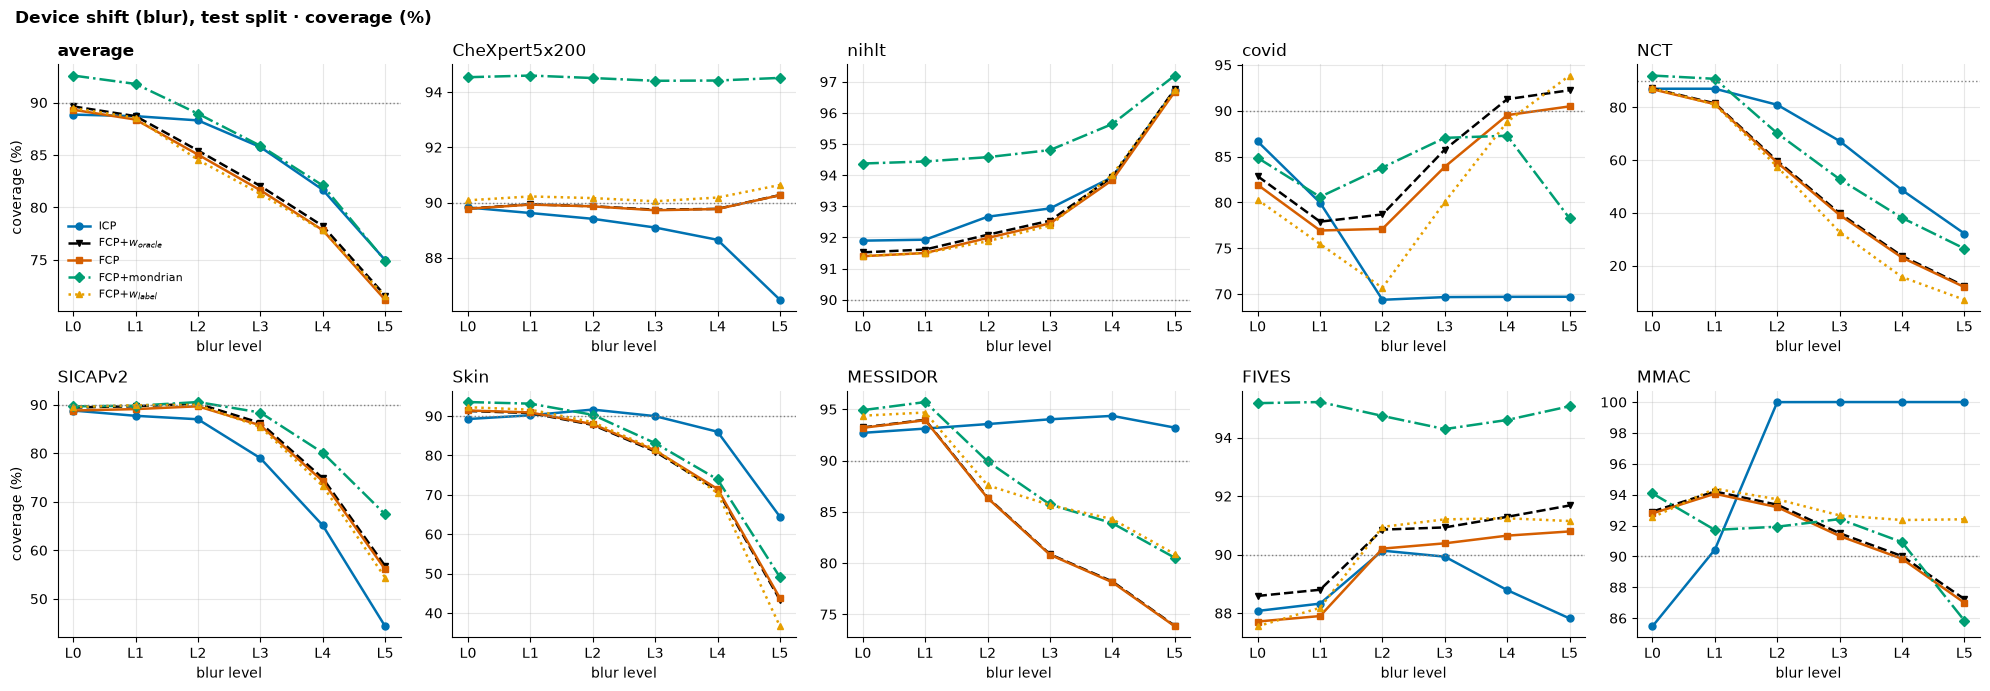

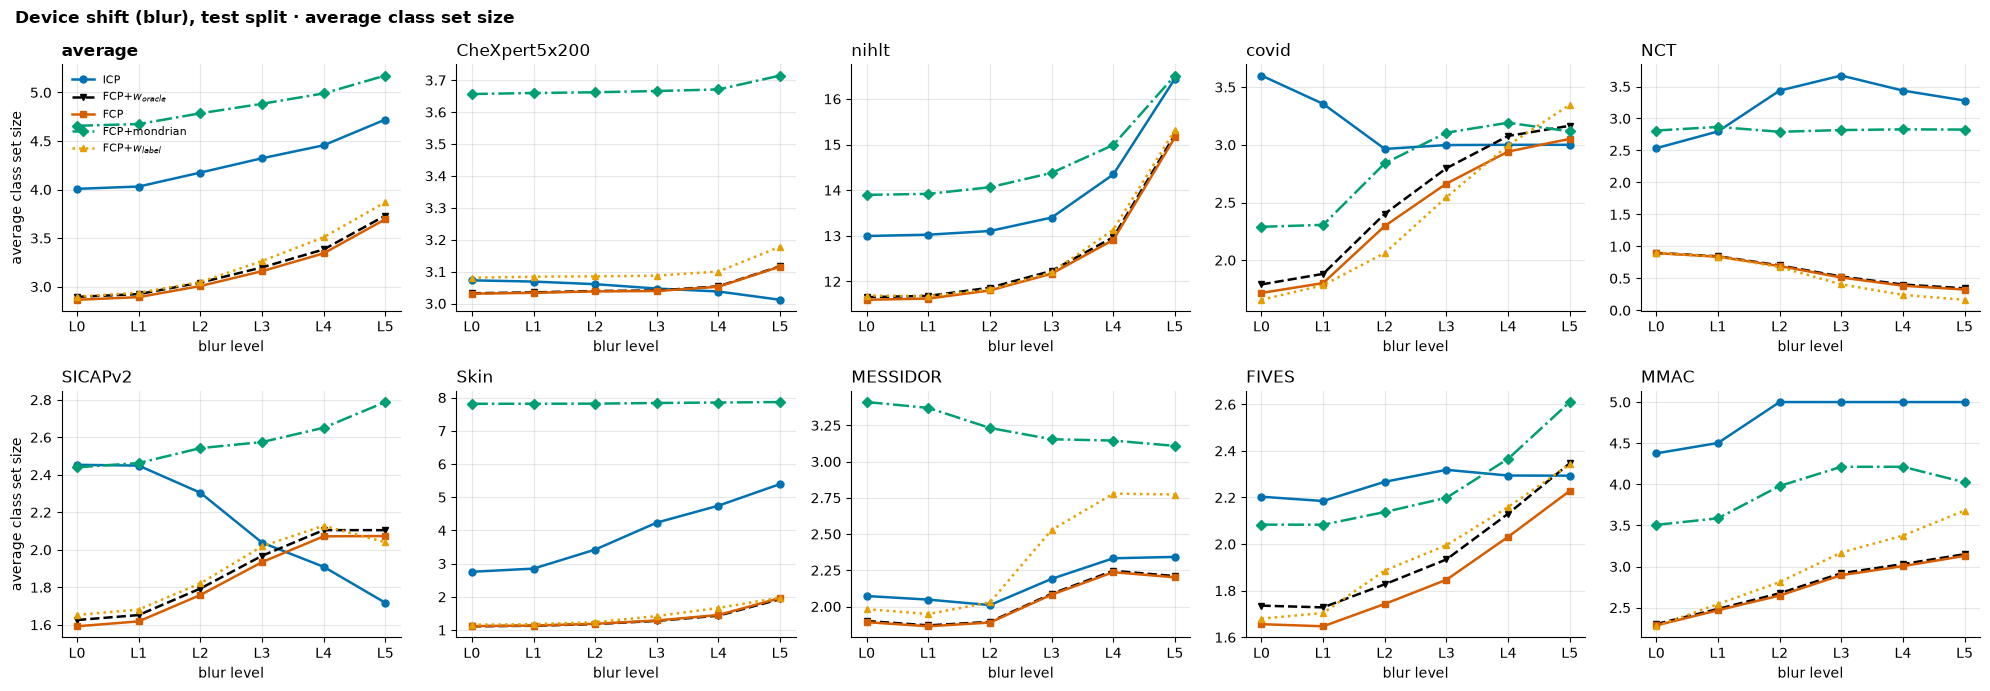

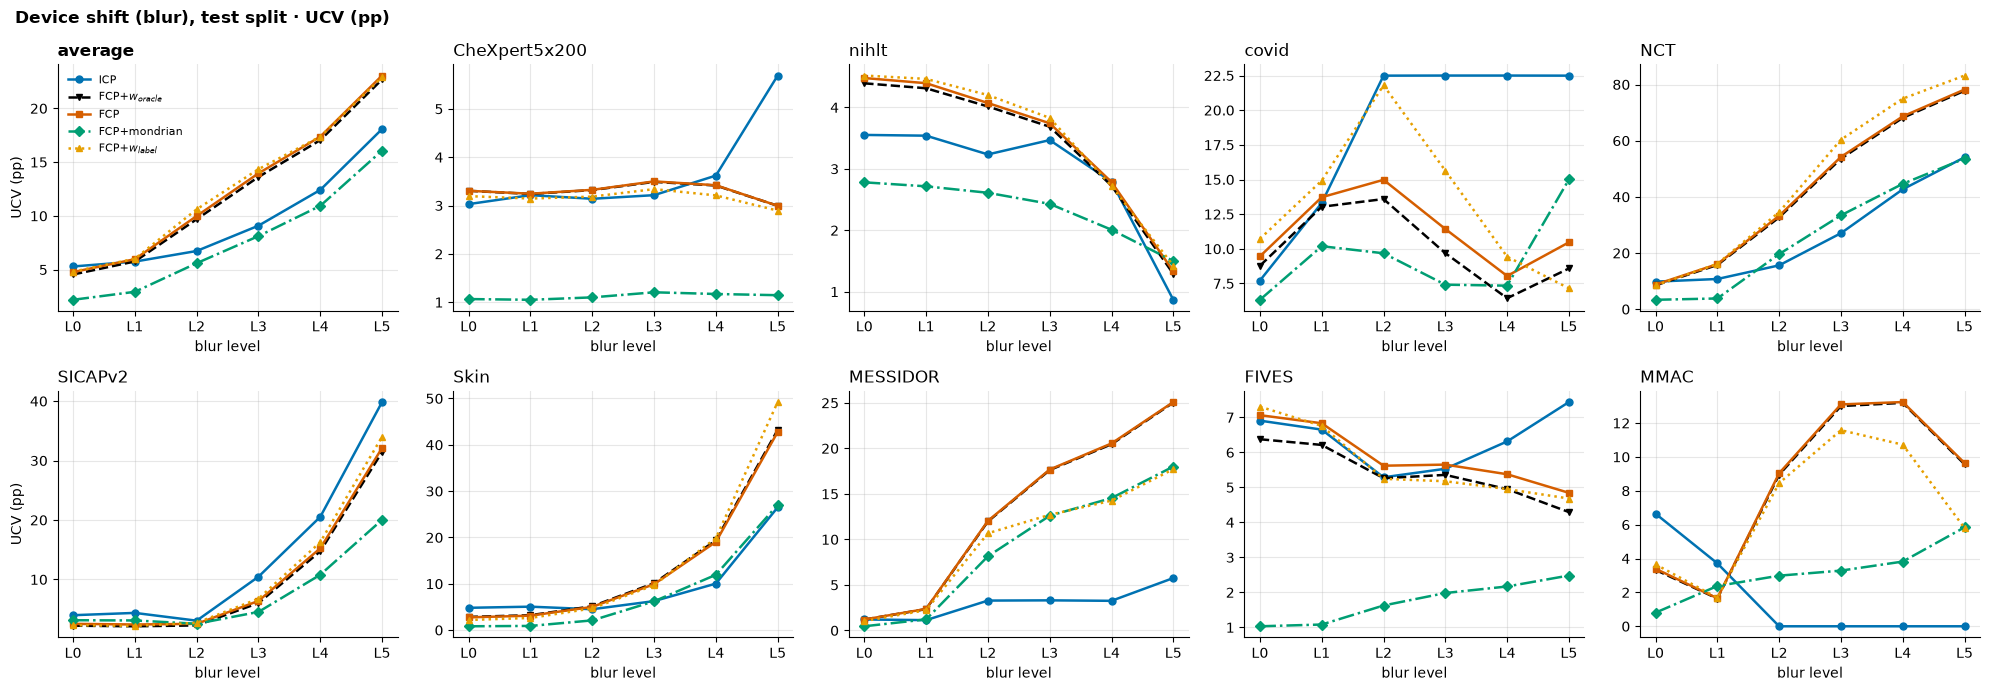

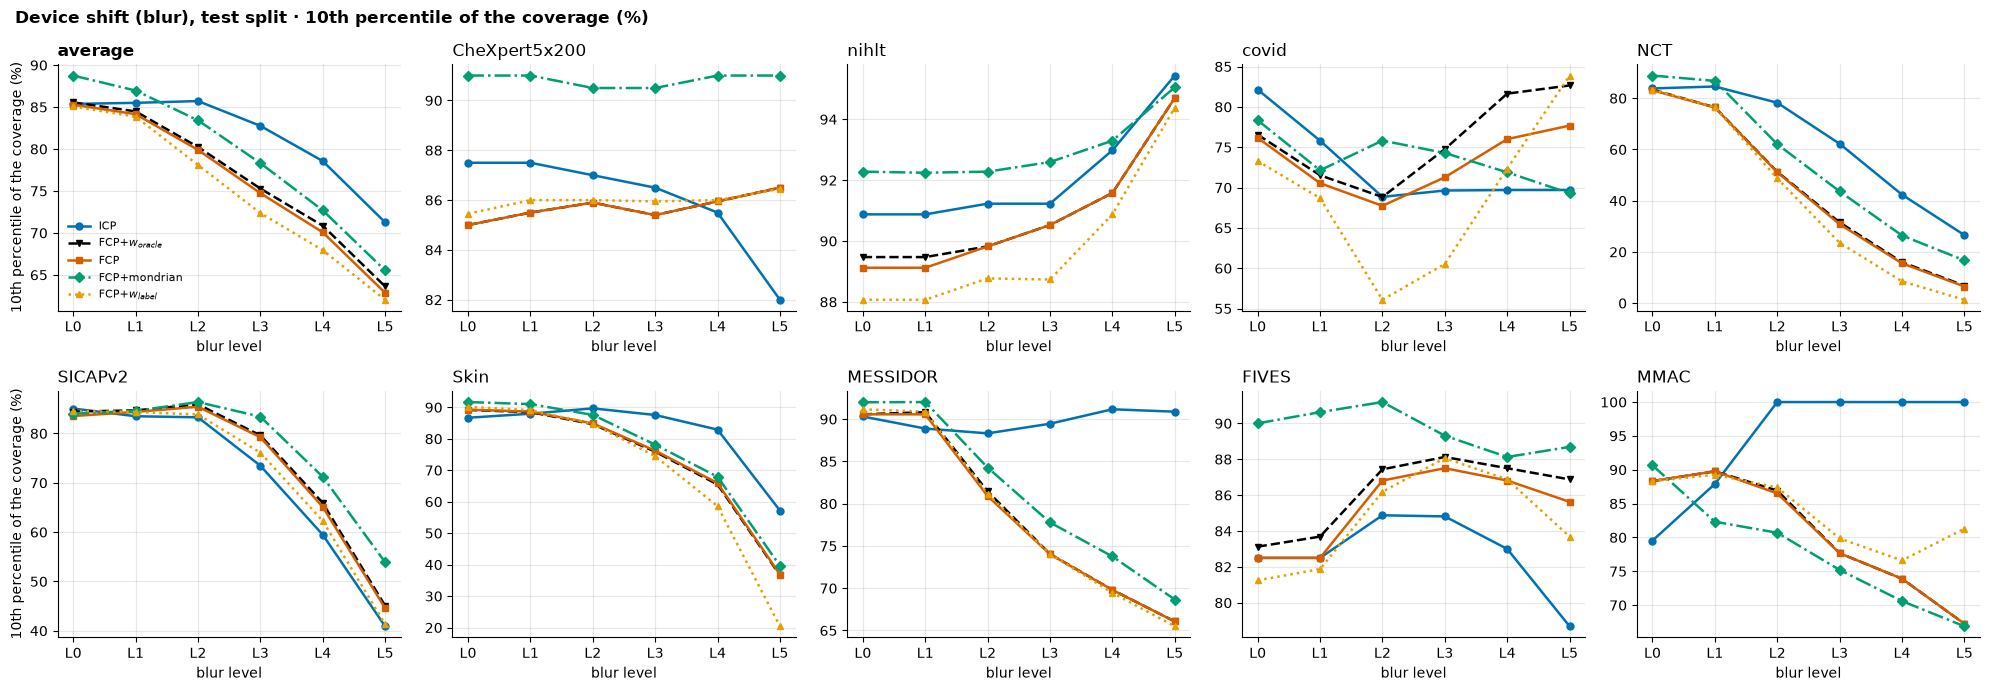

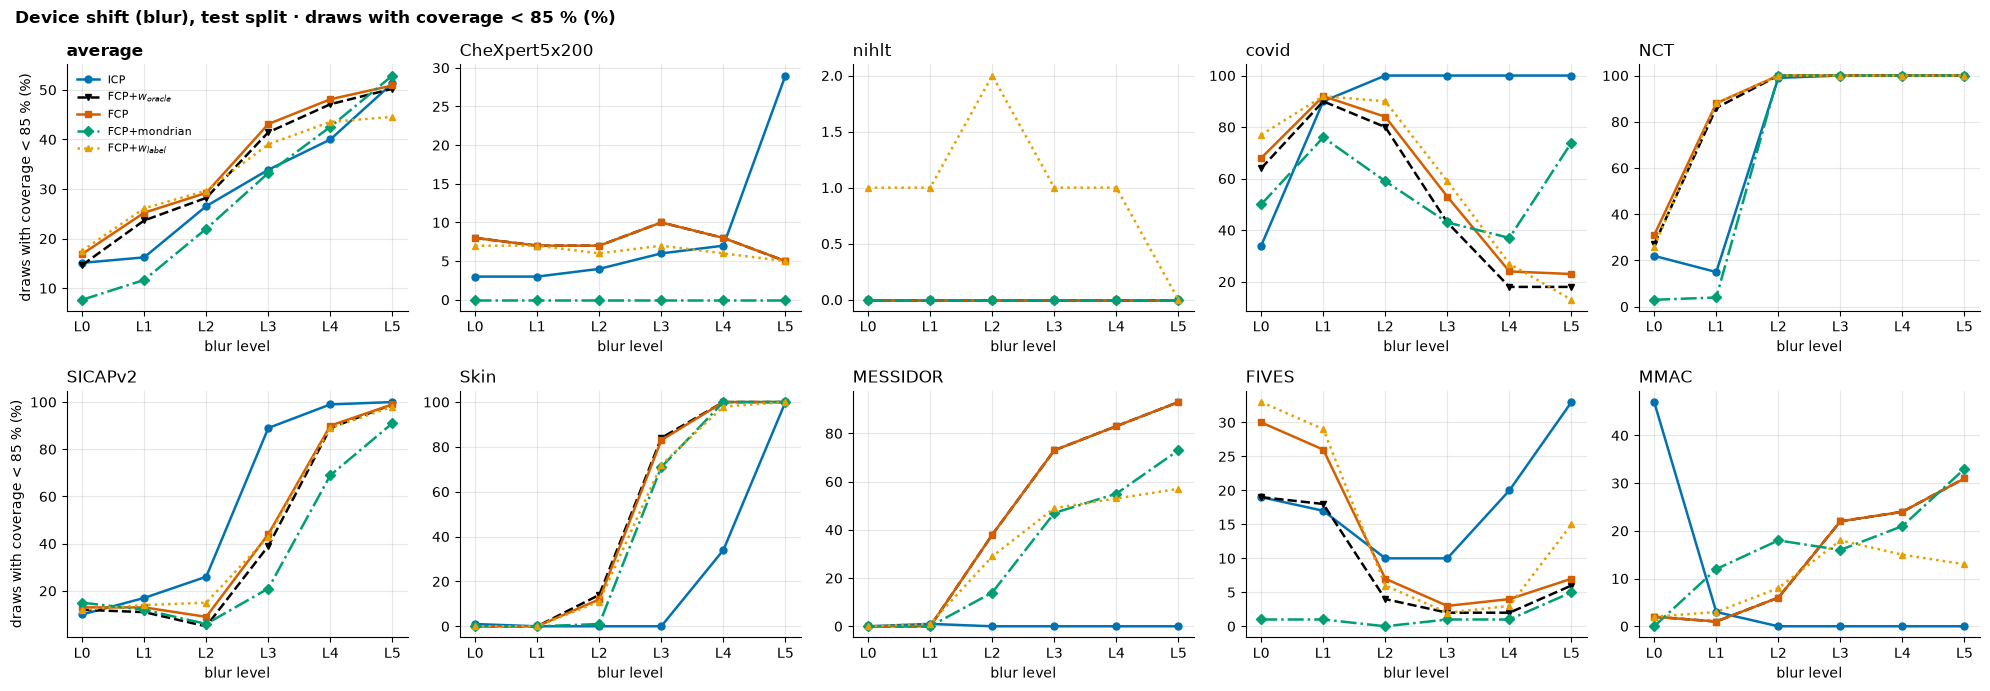

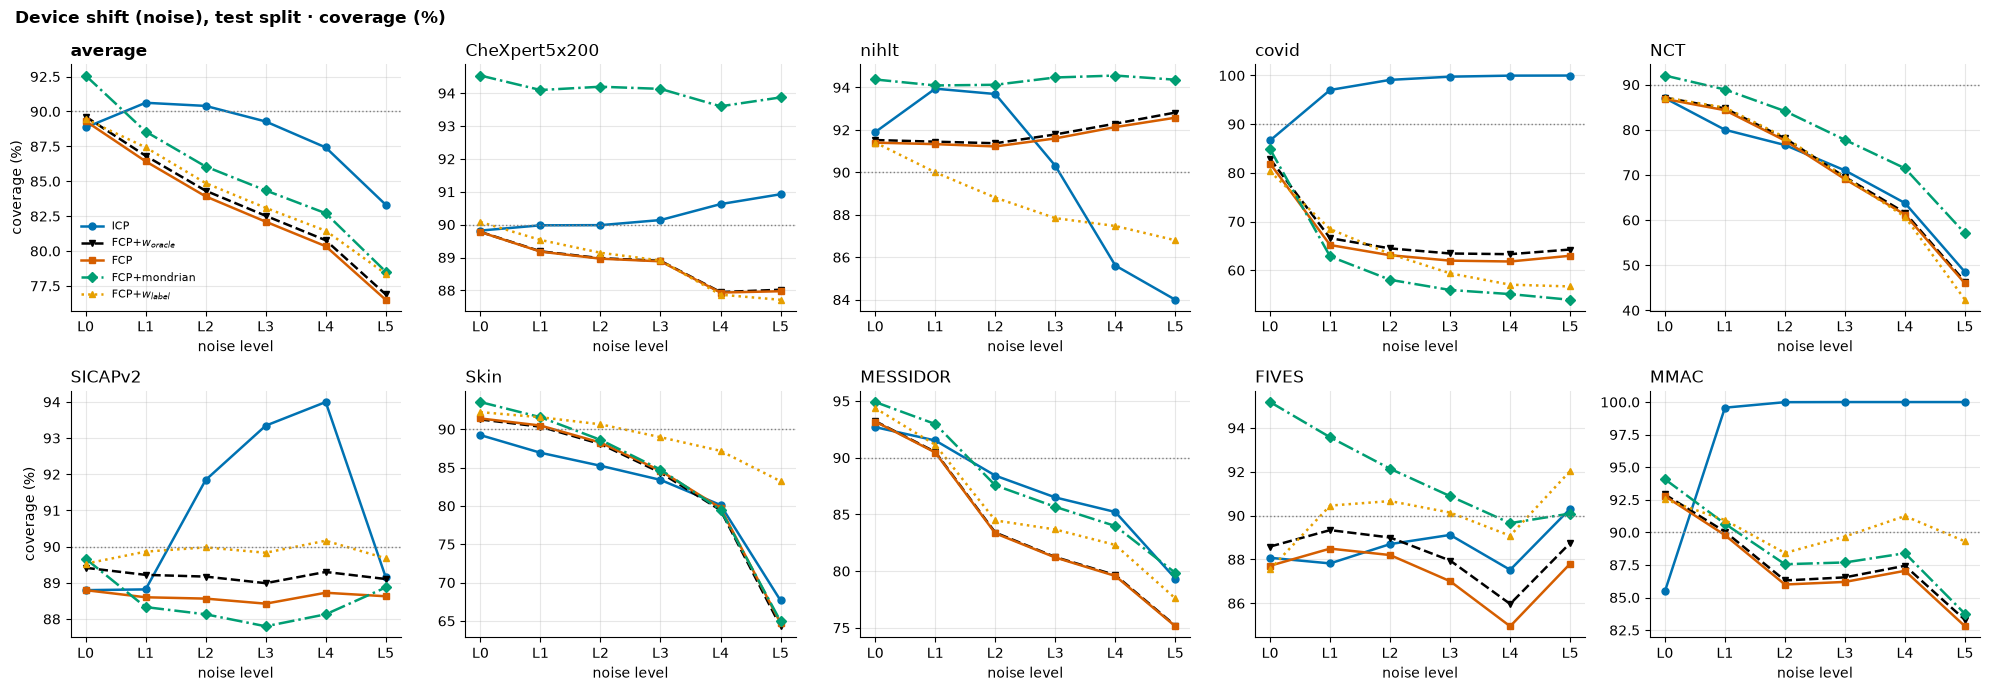

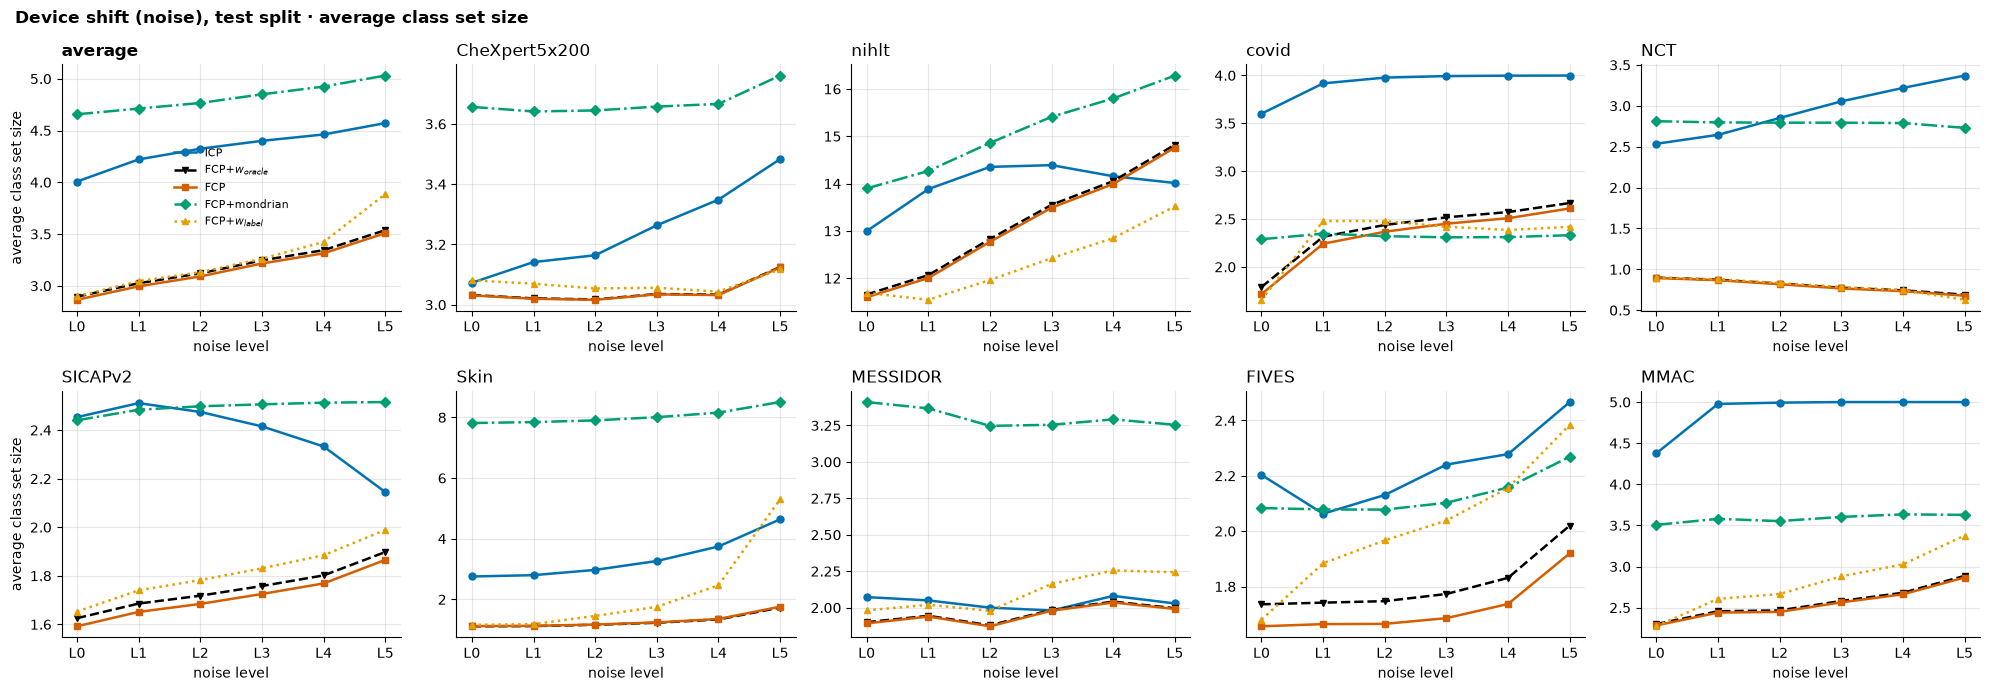

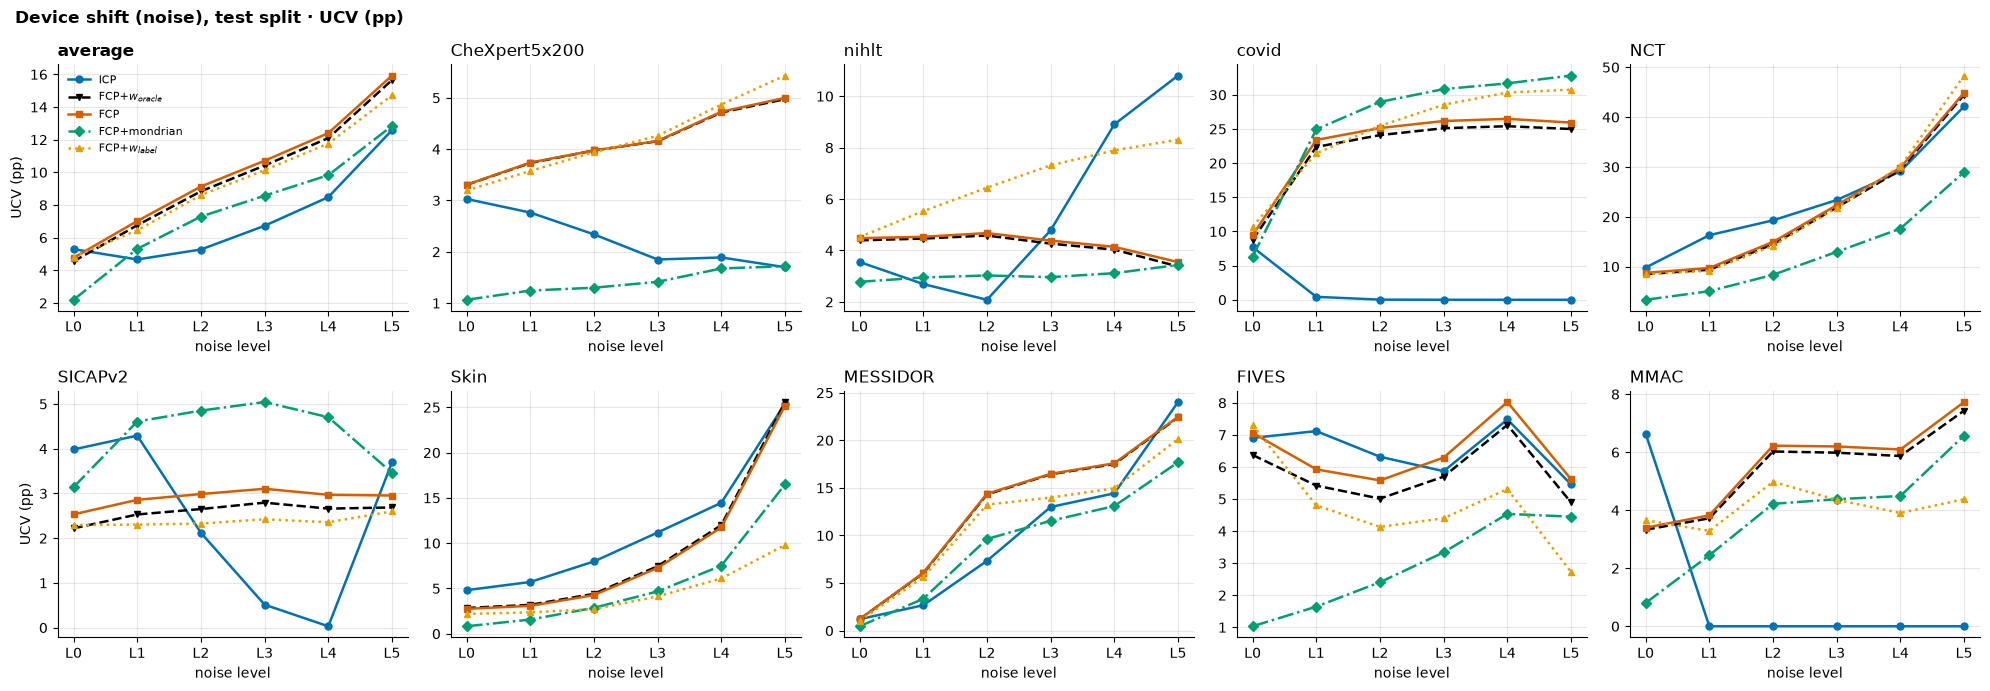

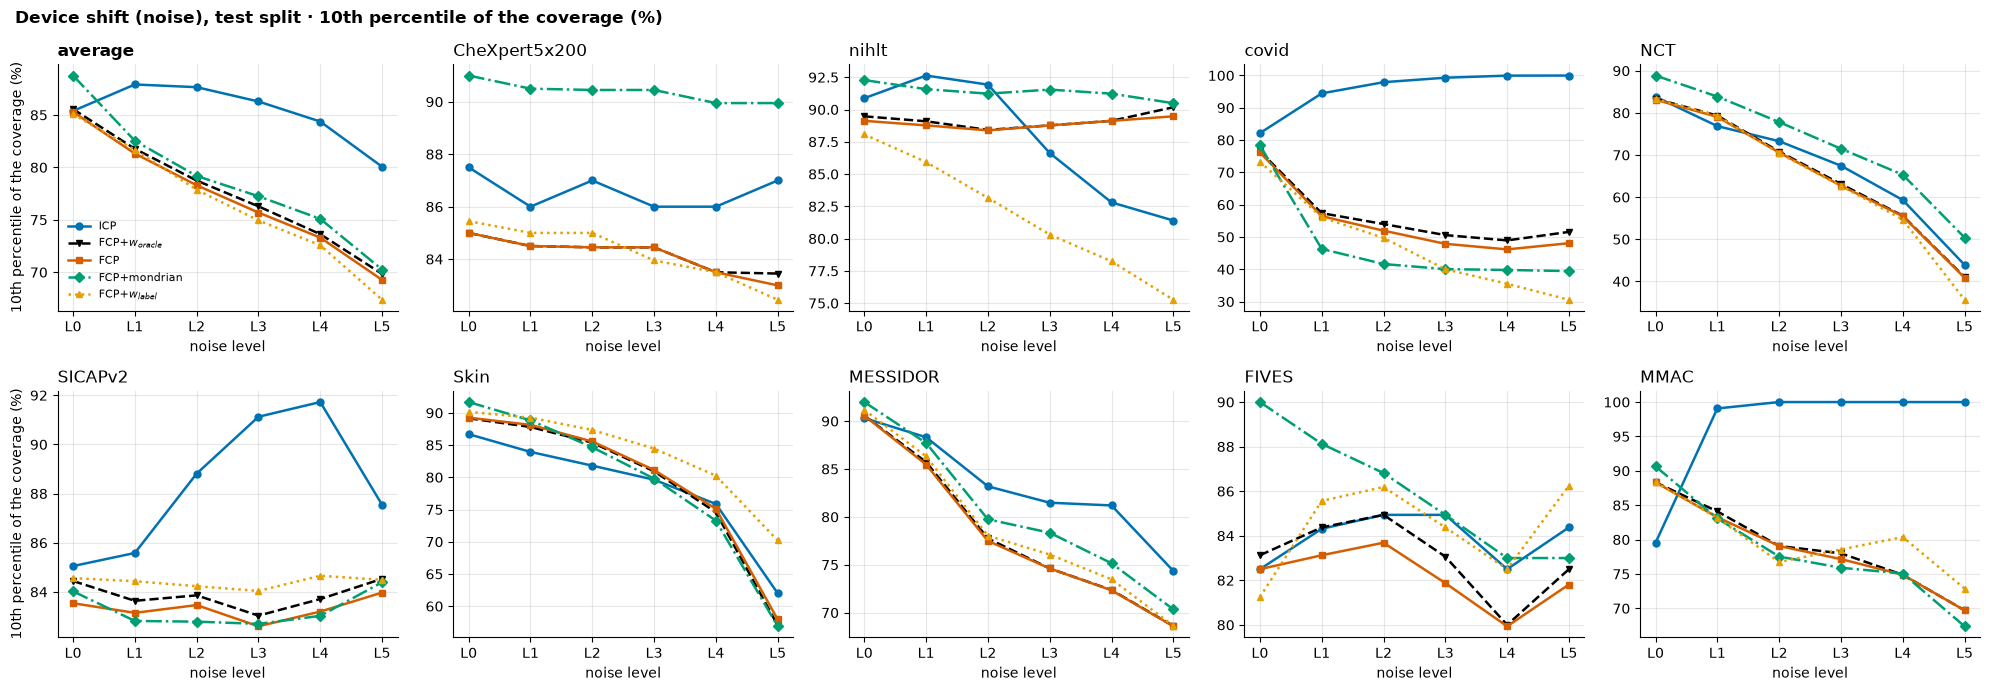

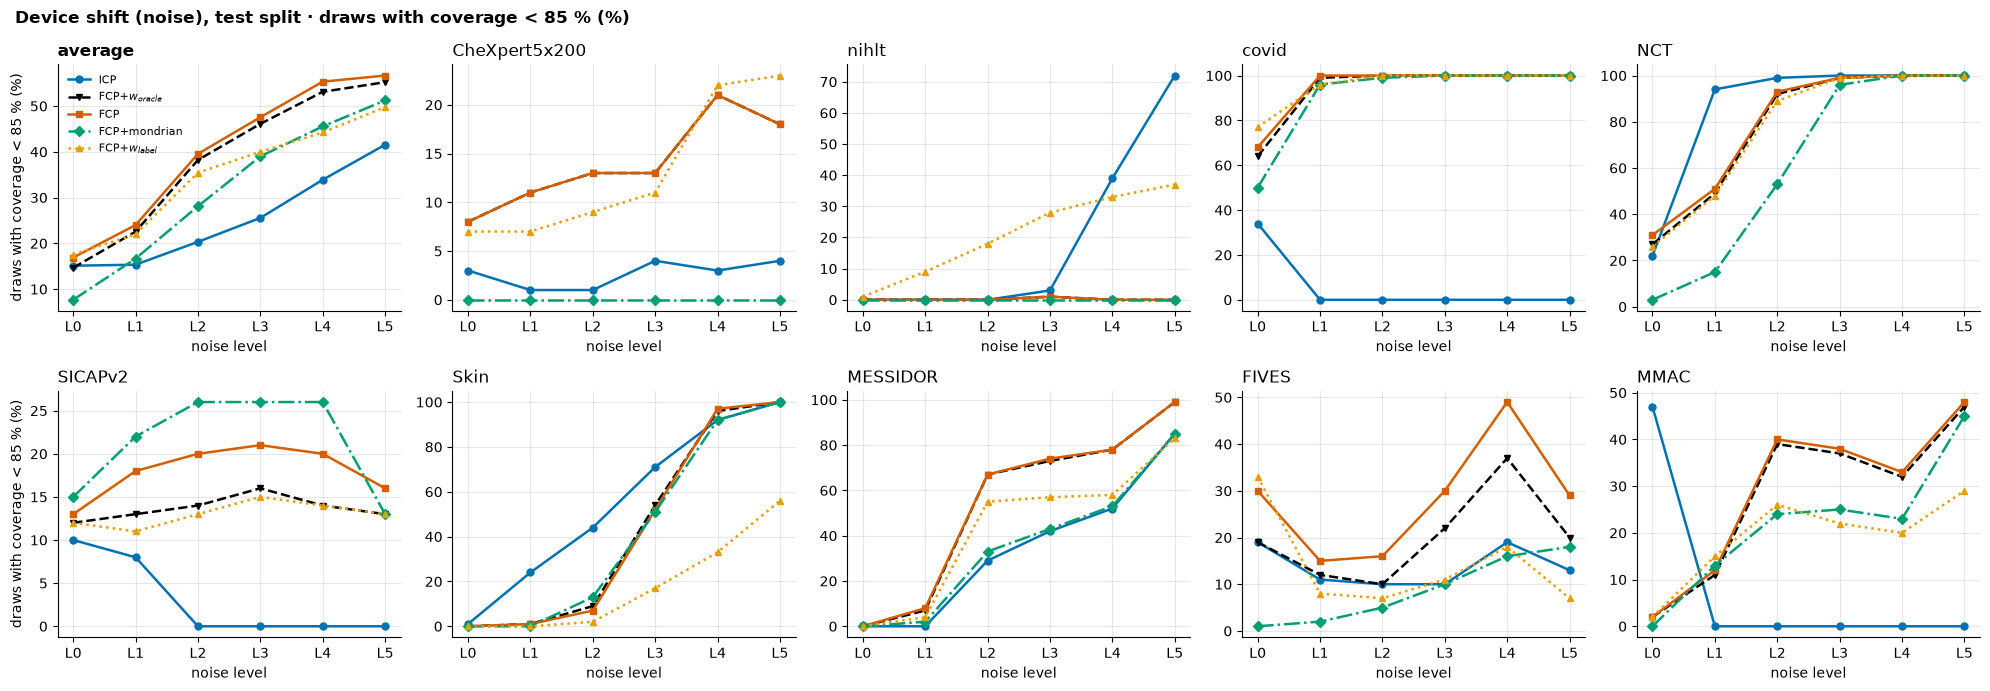

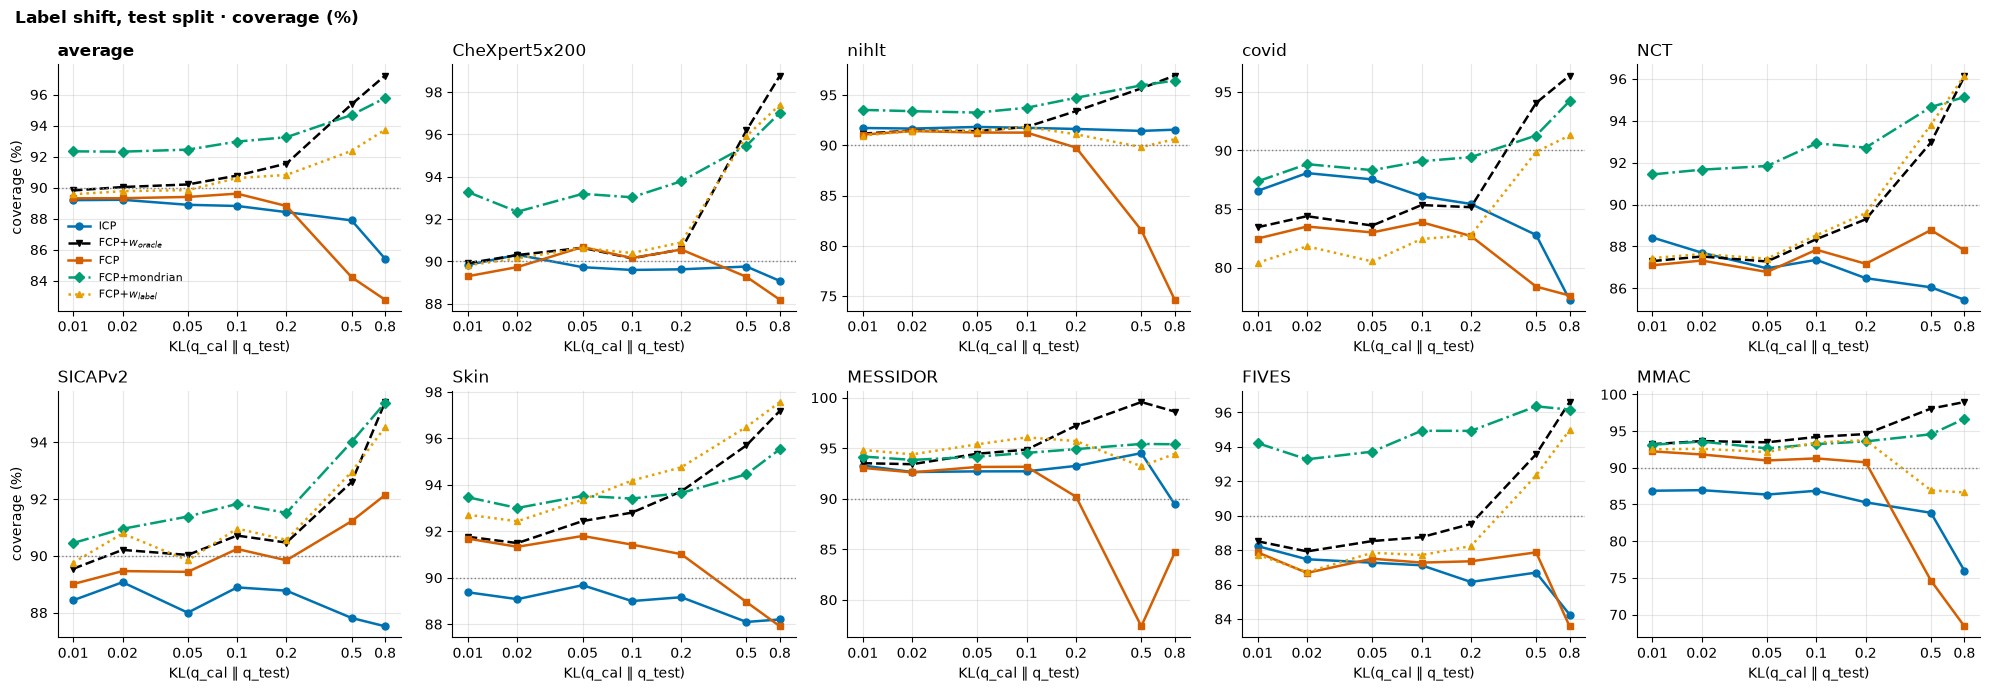

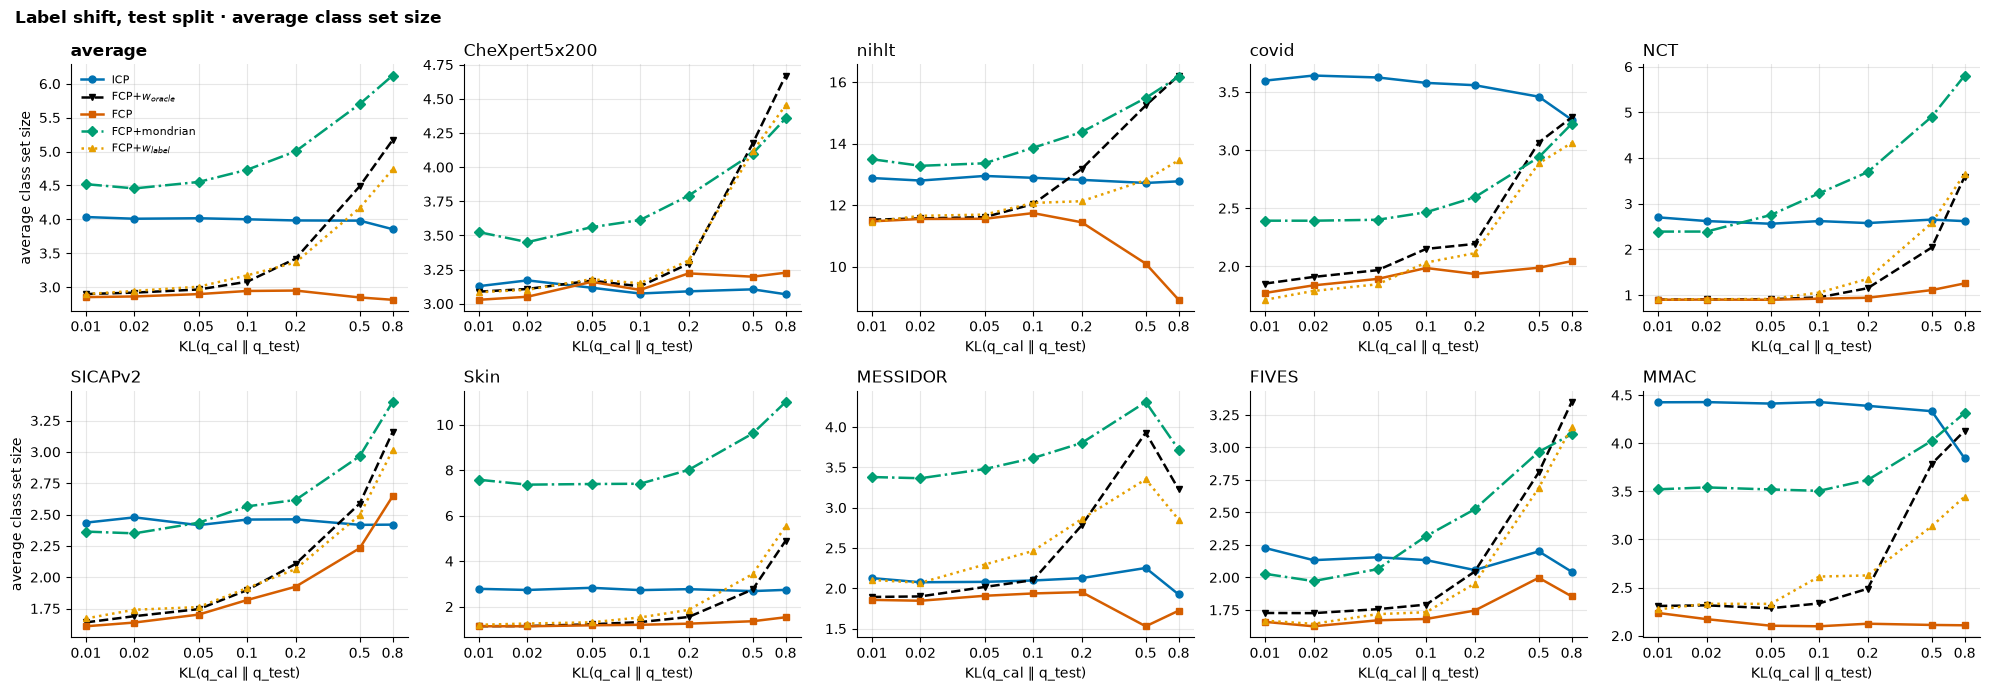

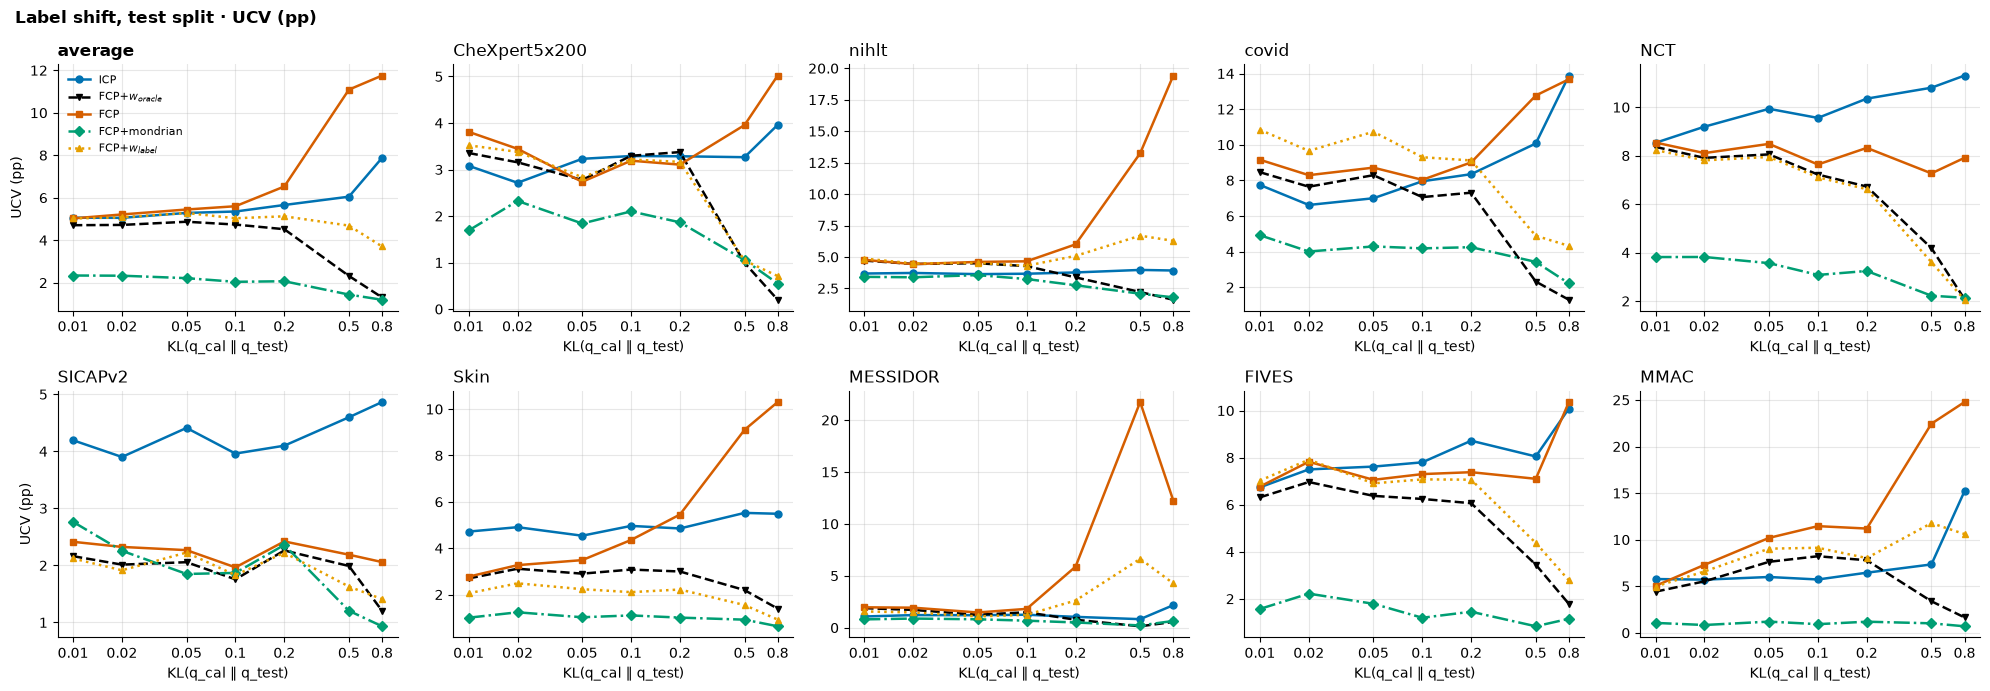

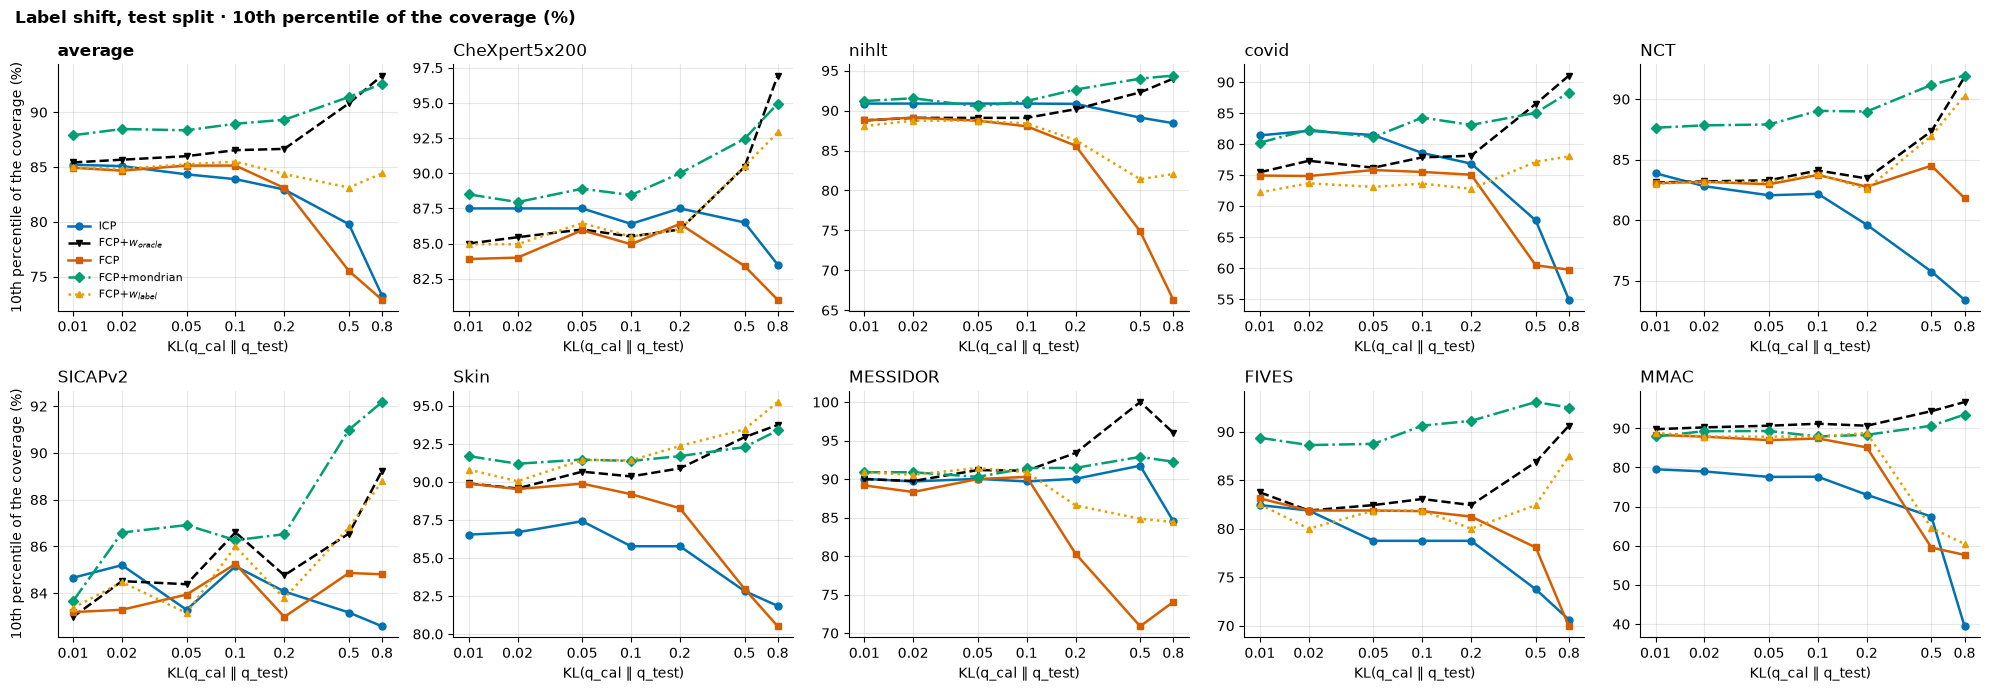

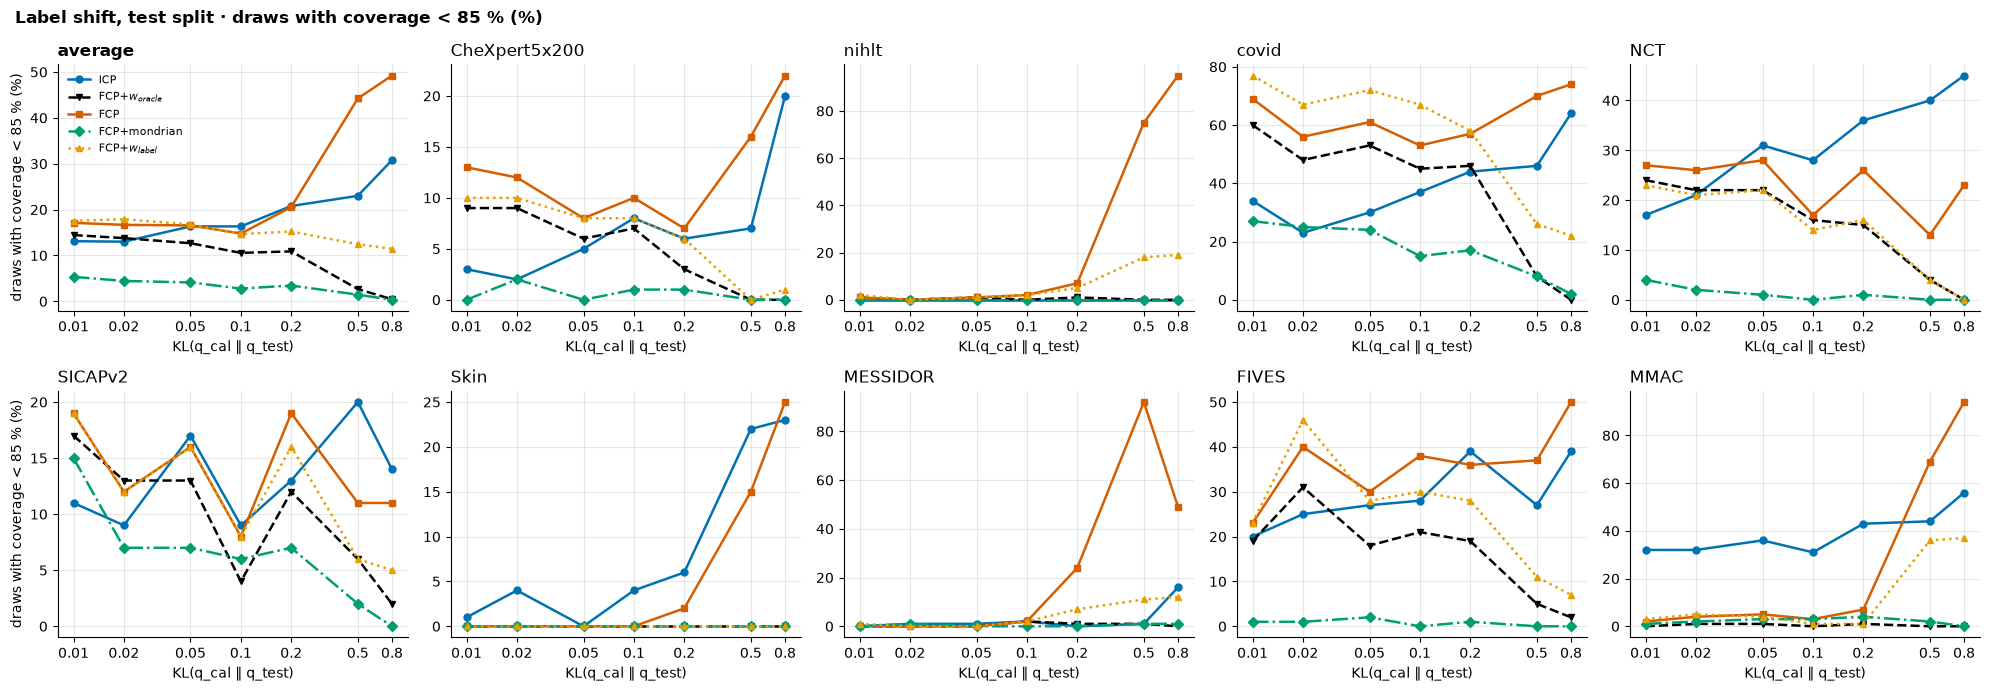

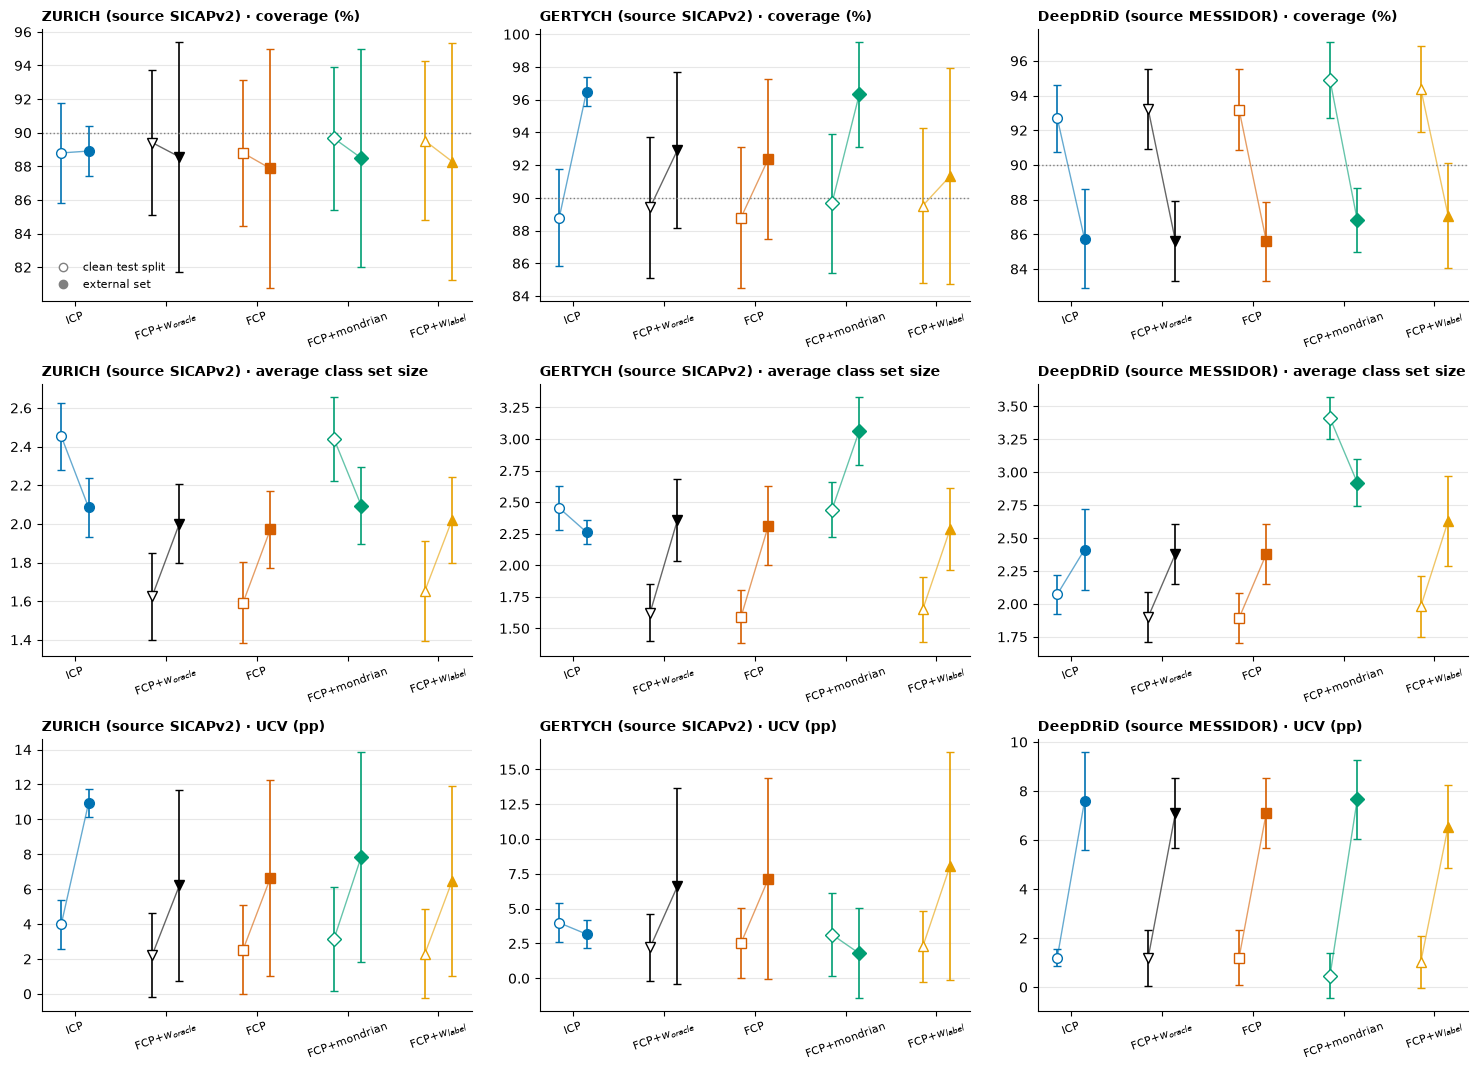

test images per draw (mean), per dataset and shift


shift,clean,blur L1,blur L2,blur L3,blur L4,blur L5,noise L1,noise L2,noise L3,noise L4,...,ZURICH,GERTYCH,DeepDRiD,label shift (KL = 0.01),label shift (KL = 0.02),label shift (KL = 0.05),label shift (KL = 0.1),label shift (KL = 0.2),label shift (KL = 0.5),label shift (KL = 0.8)
dataset,,,,,,,,,,,,,,,,,,,,,
CheXpert5x200,200.0,200.0,200.0,200.0,200.0,200.0,200.0,200.0,200.0,200.0,...,NaN,NaN,NaN,200.0,200.0,200.0,200.0,200.0,200.0,200.0
FIVES,160.0,160.0,160.0,160.0,160.0,160.0,160.0,160.0,160.0,160.0,...,NaN,NaN,NaN,160.0,160.0,160.0,160.0,160.0,160.0,160.0
MESSIDOR,351.0,351.0,351.0,351.0,351.0,351.0,351.0,351.0,351.0,351.0,...,NaN,NaN,1989.0,351.0,351.0,351.0,351.0,351.0,351.0,351.0
MMAC,215.0,215.0,215.0,215.0,215.0,215.0,215.0,215.0,215.0,215.0,...,NaN,NaN,NaN,215.0,215.0,215.0,215.0,215.0,215.0,215.0
NCT,7180.0,7180.0,7180.0,7180.0,7180.0,7180.0,7180.0,7180.0,7180.0,7180.0,...,NaN,NaN,NaN,7180.0,7180.0,7180.0,7180.0,7180.0,7180.0,7180.0
SICAPv2,2122.0,2122.0,2122.0,2122.0,2122.0,2122.0,2122.0,2122.0,2122.0,2122.0,...,703.0,413.0,NaN,2122.0,2122.0,2122.0,2122.0,2122.0,2122.0,2122.0
Skin,28039.0,28039.0,28039.0,28039.0,28039.0,28039.0,28039.0,28039.0,28039.0,28039.0,...,NaN,NaN,NaN,28039.0,28039.0,28039.0,28039.0,28039.0,28039.0,28039.0
covid,3300.0,3300.0,3300.0,3300.0,3300.0,3300.0,3300.0,3300.0,3300.0,3300.0,...,NaN,NaN,NaN,3300.0,3300.0,3300.0,3300.0,3300.0,3300.0,3300.0
nihlt,285.0,285.0,285.0,285.0,285.0,285.0,285.0,285.0,285.0,285.0,...,NaN,NaN,NaN,285.0,285.0,285.0,285.0,285.0,285.0,285.0


In [3]:
g = records.assign(below_85=100 * (records['coverage'] < 85)).groupby(['dataset', 'shift', 'method'])
per = g[['coverage', 'class_set_size', 'UCV', 'below_85', 'n_test']].mean().join(g['coverage'].quantile(0.1).rename('coverage_p10')).reset_index()
per['level'] = per['shift'].map({**{'clean': 0}, **{s: int(s[-1]) for s in DEVICE}})
per['KL'] = per['shift'].map(dict(zip(LABEL, KLS)))
per.round(3).to_csv(RESULTS_CSV.replace('.csv', '_summary.csv'), index=False)

def grid(table, x, xticks, xlabels, xlabel, title, fname, logx=False):
    groups = ['average'] + [d for d in DATASETS if d in set(table['dataset'])]
    curves = pd.concat([table.groupby(['method', x])[list(METRICS)].mean().reset_index().assign(dataset='average'), table])
    for col, ylabel in METRICS.items():
        fig, axes = plt.subplots(2, 5, figsize=(20, 7))
        for ax, ds in zip(axes.ravel(), groups):
            for m in METHODS:
                q = curves[(curves['dataset'] == ds) & (curves['method'] == m)].sort_values(x); c, ls, mk = STYLE[m]
                ax.plot(q[x], q[col], color=c, ls=ls, marker=mk, ms=5, lw=1.8, label=m)
            if col == 'coverage': ax.axhline(100 * (1 - ALPHA), color='gray', ls=':', lw=1)
            if logx: ax.set_xscale('log'); ax.minorticks_off()
            ax.set_xticks(xticks, xlabels); ax.set_xlabel(xlabel)
            ax.set_title(ds, fontweight='bold' if ds == 'average' else None, loc='left')
            ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
        for ax in axes.ravel()[len(groups):]: ax.set_visible(False)
        for ax in axes[:, 0]: ax.set_ylabel(ylabel)
        axes[0, 0].legend(fontsize=8, frameon=False)
        fig.suptitle(f'{title} · {ylabel}', fontweight='bold', x=0.01, ha='left')
        plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, f'offline_{fname}_{col}.png'), dpi=200, bbox_inches='tight'); plt.show()

for cor in CORRUPTIONS:
    grid(per[per['shift'].isin(['clean'] + [s for s in DEVICE if s.startswith(cor)])], 'level', list(range(6)),
         [f'L{l}' for l in range(6)], f'{cor} level', f'Device shift ({cor}), test split', cor)
grid(per[per['shift'].isin(LABEL)], 'KL', KLS, [f'{k:g}' for k in KLS], 'KL(q_cal ‖ q_test)', 'Label shift, test split', 'label', logx=True)

inst = records[records['kind'] == 'institution']
if len(inst):
    mets = {k: METRICS[k] for k in ['coverage', 'class_set_size', 'UCV']}
    fig, axes = plt.subplots(len(mets), len(EXTERNAL), figsize=(5 * len(EXTERNAL), 3.6 * len(mets)), squeeze=False)
    for j, (e, src) in enumerate(EXTERNAL.items()):
        both = pd.concat([records[(records['dataset'] == src) & (records['shift'] == 'clean')].assign(where='clean'),
                          inst[inst['shift'] == e].assign(where='external')])
        for i, (col, ylabel) in enumerate(mets.items()):
            ax = axes[i, j]
            for k, m in enumerate(METHODS):
                c, _, mk = STYLE[m]
                gm = both[both['method'] == m].groupby('where')[col].agg(['mean', 'std'])
                for dx, wh, fill in [(-0.15, 'clean', 'white'), (0.15, 'external', c)]:
                    if wh in gm.index:
                        ax.errorbar(k + dx, gm.loc[wh, 'mean'], yerr=gm.loc[wh, 'std'], marker=mk, color=c, mfc=fill, ms=7, capsize=3, lw=1.2)
                if {'clean', 'external'} <= set(gm.index):
                    ax.plot([k - 0.15, k + 0.15], gm.loc[['clean', 'external'], 'mean'], color=c, lw=1, alpha=0.6)
            if col == 'coverage': ax.axhline(100 * (1 - ALPHA), color='gray', ls=':', lw=1)
            ax.set_xticks(range(len(METHODS)), METHODS, rotation=20, fontsize=8)
            ax.set_title(f'{e} (source {src}) · {ylabel}', loc='left', fontsize=10, fontweight='bold')
            ax.grid(alpha=0.3, axis='y'); ax.spines[['top', 'right']].set_visible(False)
    axes[0, 0].plot([], [], 'o', color='gray', mfc='white', label=f'clean test split')
    axes[0, 0].plot([], [], 'o', color='gray', label='external set')
    axes[0, 0].legend(fontsize=8, frameon=False)
    plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'offline_institution.png'), dpi=200, bbox_inches='tight'); plt.show()

print('test images per draw (mean), per dataset and shift'); display(per.pivot_table(index='dataset', columns='shift', values='n_test').reindex(columns=SHIFTS).round(0))